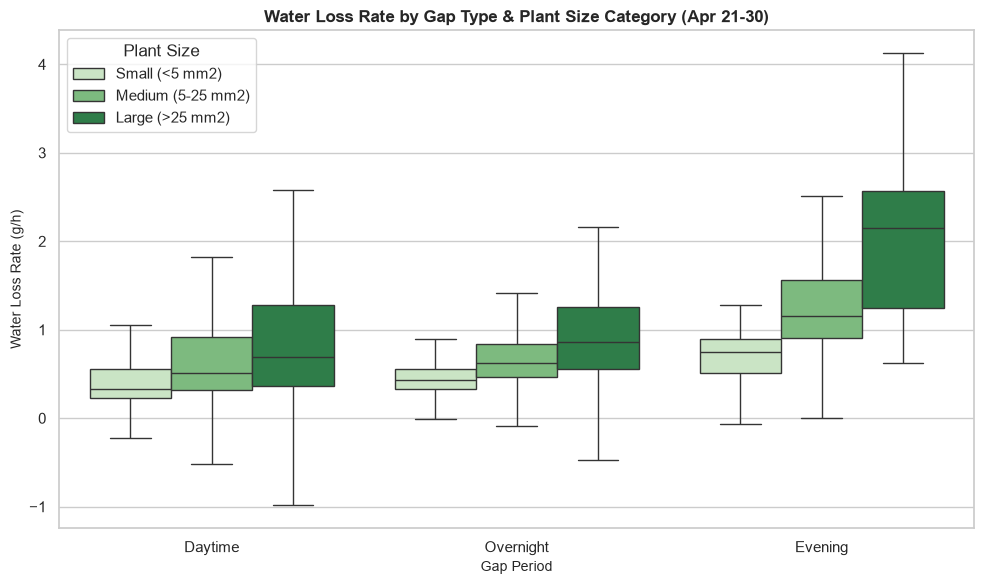

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Load Data
pw = pd.read_csv('plant-weights.csv')
design = pd.read_csv('rgb2-design.csv')
features = pd.read_csv('rgb2-features.csv')

# 2. Preprocess & Clean Window Filtering
pw['datetime'] = pd.to_datetime(pw['datetime'])
pw = pw.sort_values(by=['plant_id', 'datetime']).reset_index(drop=True)
plant_meta = design[['plant_id', 'genotype', 'treatment']].drop_duplicates()
pw = pw.merge(plant_meta, on='plant_id', how='left')

pw_clean = pw[
    (pw['datetime'] >= '2026-04-21')
    & (pw['datetime'] <= '2026-04-30 23:59:59')
].copy()
pw_clean['prev_weight_after'] = pw_clean.groupby('plant_id')[
    'weight_after_watering_g'
].shift(1)
pw_clean['prev_datetime'] = pw_clean.groupby('plant_id')['datetime'].shift(1)
pw_clean['time_gap_hours'] = (
    pw_clean['datetime'] - pw_clean['prev_datetime']
).dt.total_seconds() / 3600.0
pw_clean['water_loss_g'] = (
    pw_clean['prev_weight_after'] - pw_clean['weight_g']
)
pw_clean['water_loss_rate_g_per_h'] = (
    pw_clean['water_loss_g'] / pw_clean['time_gap_hours']
)


def get_gap_type(dt):
  hour = dt.hour
  if 6 <= hour < 17:
    return 'Daytime'
  elif 17 <= hour < 22:
    return 'Evening'
  else:
    return 'Overnight'


pw_clean['gap_type'] = pw_clean['datetime'].apply(get_gap_type)

# 3. Merge Plant Size (Leaf Area)
features['datetime'] = pd.to_datetime(features['datetime'])
features_clean = features[
    (features['datetime'] >= '2026-04-21')
    & (features['datetime'] <= '2026-04-30 23:59:59')
]
plant_area = (
    features_clean.groupby('plant_id')['area_mm2']
    .mean()
    .reset_index(name='mean_area_mm2')
)
pw_clean = pw_clean.merge(plant_area, on='plant_id', how='left')

# Categorize Plant Size
pw_clean['size_category'] = pd.cut(
    pw_clean['mean_area_mm2'],
    bins=[-np.inf, 5, 25, np.inf],
    labels=['Small (<5 mm2)', 'Medium (5-25 mm2)', 'Large (>25 mm2)'],
)

# 4. Plot Water Loss by Gap Type and Plant Size
sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=pw_clean,
    x='gap_type',
    y='water_loss_rate_g_per_h',
    hue='size_category',
    palette='Greens',
    showfliers=False,
    ax=ax,
)

ax.set_title(
    'Water Loss Rate by Gap Type & Plant Size Category (Apr 21-30)',
    fontsize=12,
    fontweight='bold',
)
ax.set_xlabel('Gap Period', fontsize=10)
ax.set_ylabel('Water Loss Rate (g/h)', fontsize=10)
plt.legend(title='Plant Size')
plt.tight_layout()
plt.savefig('water_loss_by_plant_size.png', dpi=300)
plt.show()